# Eksploracyjna analiza danych (EDA) — ceny domów w Ames, Iowa

**Zajęcia 5 — Eksploracja danych**

Zbiór: [Kaggle — House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)
(D. De Cock, *Ames Housing*, 2011). 1460 transakcji z lat 2006–2010, 81 kolumn.

**Cel:** przeprowadzić EDA, odkryć interesujące zależności i przedstawić najważniejsze wnioski na wykresach.

Plan notatnika:
1. Wczytanie danych i pytania naprowadzające
2. Statystyki opisowe, typy danych, braki danych (i co one znaczą)
3. Analiza zmiennej docelowej `SalePrice`
4. Wykresy z wykładu (pudełkowy, słupkowy, liniowy, punktowy, mapa korelacji)
5. Co wpływa na cenę domu? — hipoteza „większe domy są droższe”
6. Wnioski

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 90)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Wczytanie danych

In [2]:
df = pd.read_csv("train.csv")
print("Wymiary:", df.shape)
df.head()

Wymiary: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.00,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.00",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.00",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.00",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.00",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.00,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.00",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Pytania naprowadzające

**Jaka jest zmienna docelowa?** — `SalePrice`, cena sprzedaży domu w USD. Chcemy ją przewidywać na podstawie cech domu.
Pozostałe kolumny to identyfikator `Id` i 79 cech opisujących nieruchomość.

**Jakie rodzaje zmiennych są w zbiorze?** Poniżej podział według typów w pandas i według znaczenia.

In [3]:
features = df.drop(columns=["Id", "SalePrice"])
num_cols = features.select_dtypes(include="number").columns.tolist()
cat_cols = features.select_dtypes(exclude="number").columns.tolist()

print(f"Cechy liczbowe (int/float): {len(num_cols)}")
print(f"Cechy tekstowe/kategoryczne (object): {len(cat_cols)}")
df.dtypes.value_counts()

Cechy liczbowe (int/float): 36
Cechy tekstowe/kategoryczne (object): 43


object     43
int64      35
float64     3
Name: count, dtype: int64

Typ w pandas to nie to samo co rodzaj zmiennej. Kilka przykładów:

| Rodzaj | Przykłady | Uwagi |
|---|---|---|
| **liczbowe ciągłe** | `GrLivArea`, `LotArea`, `TotalBsmtSF`, `SalePrice` | powierzchnie w stopach², cena w USD |
| **liczbowe dyskretne** | `FullBath`, `BedroomAbvGr`, `GarageCars`, `YearBuilt` | liczby pokoi/łazienek, lata |
| **porządkowe (liczbowo)** | `OverallQual`, `OverallCond` | skala 1–10 |
| **porządkowe (tekstowo)** | `ExterQual`, `KitchenQual`, `BsmtQual` | Po < Fa < TA < Gd < Ex |
| **nominalne (liczbowo!)** | `MSSubClass` | kody typu budynku — liczby, ale bez porządku |
| **nominalne** | `Neighborhood`, `BldgType`, `SaleCondition` | kategorie bez porządku |

Zmiennych czysto tekstowych (wolny tekst) w zbiorze nie ma — wszystkie kolumny `object` to kategorie.

In [4]:
df[["MSSubClass", "OverallQual", "ExterQual", "Neighborhood", "BldgType"]].nunique()

MSSubClass      15
OverallQual     10
ExterQual        4
Neighborhood    25
BldgType         5
dtype: int64

### Zakres danych — czy to tylko domy jednorodzinne?
Na wykładzie: zbiór zawiera też szeregowce, bliźniaki i domy dwurodzinne, ale nie mieszkania w blokach.

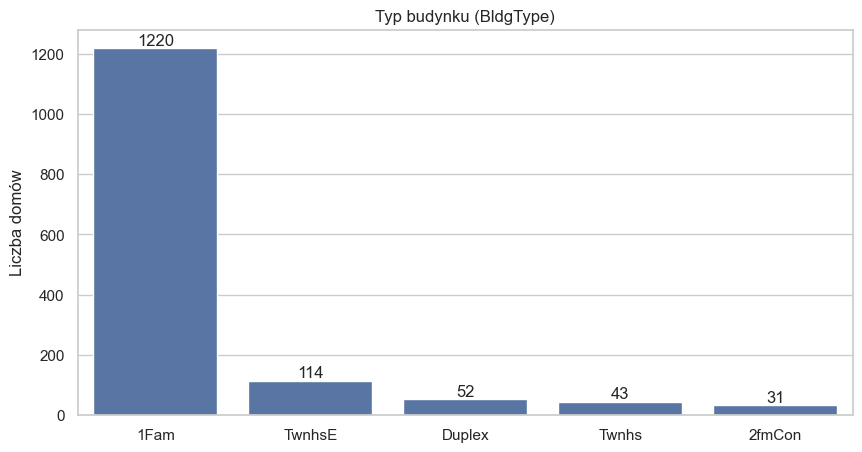

In [5]:
ax = sns.countplot(data=df, x="BldgType", order=df["BldgType"].value_counts().index)
ax.set(title="Typ budynku (BldgType)", xlabel="", ylabel="Liczba domów")
for c in ax.containers:
    ax.bar_label(c)
plt.show()

## 2. Statystyki opisowe, typy danych i braki

### `df.describe()` — zmienne liczbowe

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,"1,460.00",730.50,421.61,1.00,365.75,730.50,"1,095.25","1,460.00"
MSSubClass,"1,460.00",56.90,42.30,20.00,20.00,50.00,70.00,190.00
LotFrontage,"1,201.00",70.05,24.28,21.00,59.00,69.00,80.00,313.00
LotArea,"1,460.00","10,516.83","9,981.26","1,300.00","7,553.50","9,478.50","11,601.50","215,245.00"
OverallQual,"1,460.00",6.10,1.38,1.00,5.00,6.00,7.00,10.00
OverallCond,"1,460.00",5.58,1.11,1.00,5.00,5.00,6.00,9.00
YearBuilt,"1,460.00","1,971.27",30.20,"1,872.00","1,954.00","1,973.00","2,000.00","2,010.00"
YearRemodAdd,"1,460.00","1,984.87",20.65,"1,950.00","1,967.00","1,994.00","2,004.00","2,010.00"
MasVnrArea,"1,452.00",103.69,181.07,0.00,0.00,0.00,166.00,"1,600.00"
BsmtFinSF1,"1,460.00",443.64,456.10,0.00,0.00,383.50,712.25,"5,644.00"


### `df.describe()` — zmienne kategoryczne

In [7]:
df.describe(include='object').T

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


### `df.dtypes` — typy wszystkich kolumn

In [8]:
with pd.option_context("display.max_rows", 100):
    display(df.dtypes.to_frame("dtype").T)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
dtype,int64,int64,object,float64,int64,object,object,object,object,object,object,object,object,object,object,object,object,int64,int64,int64,int64,object,object,object,object,object,float64,object,object,object,object,object,object,object,int64,object,int64,int64,int64,object,object,object,object,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,object,int64,object,int64,object,object,float64,object,int64,int64,object,object,object,int64,int64,int64,int64,int64,int64,object,object,object,int64,int64,int64,object,object,int64


### Braki danych — `df.isna().sum()`

In [9]:
na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
na_df = pd.DataFrame({"braki": na, "procent": (na / len(df) * 100).round(1)})
na_df

,braki,procent
PoolQC,1453,99.50
MiscFeature,1406,96.30
Alley,1369,93.80
Fence,1179,80.80
MasVnrType,872,59.70
FireplaceQu,690,47.30
LotFrontage,259,17.70
GarageType,81,5.50
GarageYrBlt,81,5.50
GarageFinish,81,5.50


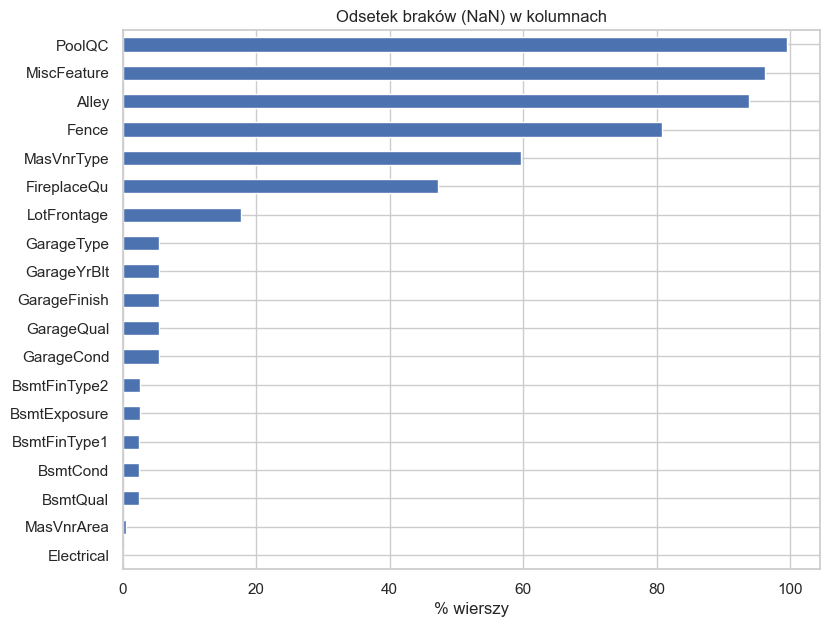

In [10]:
ax = na_df["procent"].plot.barh(figsize=(9, 7))
ax.invert_yaxis()
ax.set(title="Odsetek braków (NaN) w kolumnach", xlabel="% wierszy")
plt.show()

### Pułapka: NA nie zawsze znaczy „brak danych”

Według `data_description.txt` w wielu kolumnach `NA` oznacza **brak danej cechy domu**, a nie brak informacji:

| Kolumny | NA oznacza |
|---|---|
| `PoolQC` | brak basenu |
| `MiscFeature` | brak dodatkowych elementów |
| `Alley` | brak dostępu przez alejkę |
| `Fence` | brak ogrodzenia |
| `FireplaceQu` | brak kominka |
| `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond` | brak garażu |
| `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2` | brak piwnicy |

`pd.read_csv()` domyślnie zamienia tekst `"NA"` na `NaN` — **a także tekst `"None"`!**
Dlatego `MasVnrType` (gdzie `None` = brak okładziny) ma aż 872 „braki”.

Sprawdźmy to na danych:

In [11]:
raw = pd.read_csv("train.csv", keep_default_na=False)   # wczytanie bez konwersji na NaN
for col in ["PoolQC", "Alley", "FireplaceQu", "GarageType", "MasVnrType", "Electrical", "LotFrontage"]:
    print(f"{col:12s}", raw[col].value_counts().head(5).to_dict())

PoolQC       {'NA': 1453, 'Gd': 3, 'Ex': 2, 'Fa': 2}
Alley        {'NA': 1369, 'Grvl': 50, 'Pave': 41}
FireplaceQu  {'NA': 690, 'Gd': 380, 'TA': 313, 'Fa': 33, 'Ex': 24}
GarageType   {'Attchd': 870, 'Detchd': 387, 'BuiltIn': 88, 'NA': 81, 'Basment': 19}
MasVnrType   {'None': 864, 'BrkFace': 445, 'Stone': 128, 'BrkCmn': 15, 'NA': 8}
Electrical   {'SBrkr': 1334, 'FuseA': 94, 'FuseF': 27, 'FuseP': 3, 'Mix': 1}
LotFrontage  {'NA': 259, '60': 143, '70': 70, '80': 69, '50': 57}


In [12]:
# Spójność: NA w kolumnach garażu tam, gdzie GarageArea == 0? NA w PoolQC tam, gdzie PoolArea == 0?
print("Garaż:   NaN w GarageType =", df["GarageType"].isna().sum(),
      "| GarageArea == 0 =", (df["GarageArea"] == 0).sum())
print("Basen:   NaN w PoolQC     =", df["PoolQC"].isna().sum(),
      "| PoolArea == 0   =", (df["PoolArea"] == 0).sum())
print("Kominek: NaN w FireplaceQu=", df["FireplaceQu"].isna().sum(),
      "| Fireplaces == 0 =", (df["Fireplaces"] == 0).sum())
print("Piwnica: NaN w BsmtQual   =", df["BsmtQual"].isna().sum(),
      "| TotalBsmtSF == 0 =", (df["TotalBsmtSF"] == 0).sum())
print("Piwnica: NaN w BsmtExposure =", df["BsmtExposure"].isna().sum(), "→ 1 prawdziwy brak (piwnica jest, ekspozycji nie podano)")

Garaż:   NaN w GarageType = 81 | GarageArea == 0 = 81
Basen:   NaN w PoolQC     = 1453 | PoolArea == 0   = 1453
Kominek: NaN w FireplaceQu= 690 | Fireplaces == 0 = 690
Piwnica: NaN w BsmtQual   = 37 | TotalBsmtSF == 0 = 37
Piwnica: NaN w BsmtExposure = 38 → 1 prawdziwy brak (piwnica jest, ekspozycji nie podano)


**Wniosek:** prawdziwych braków jest niewiele:
- `LotFrontage` (259) — długość frontu działki, naprawdę nieznana,
- `MasVnrType`/`MasVnrArea` (8) — nieznana okładzina,
- `Electrical` (1), `BsmtExposure` i `BsmtFinType2` (po 1).
- `GarageYrBlt` (81) — NaN, bo nie ma garażu (nie da się podać roku budowy).

Przygotujmy poprawioną wersję danych: „brak cechy” → kategoria `"None"`, prawdziwe braki zostają jako NaN.
Usuwanie wierszy albo wstawianie średniej/mody w kolumnach typu `PoolQC` byłoby błędem.

In [13]:
df_clean = df.copy()

none_means_absent = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
                     "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                     "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]

# prawdziwe braki w piwnicy: piwnica jest (BsmtQual podane), a mimo to kolumna pusta -> zostaw NaN
real_bsmt_na = {c: df[c].isna() & df["BsmtQual"].notna() for c in ["BsmtExposure", "BsmtFinType2"]}

df_clean[none_means_absent] = df_clean[none_means_absent].fillna("None")
for c, m in real_bsmt_na.items():
    df_clean.loc[m, c] = np.nan

# MasVnrType: tekst "None" (brak okładziny) pandas zamienił na NaN -> bierzemy wartości z surowego pliku
df_clean["MasVnrType"] = raw["MasVnrType"].replace("NA", np.nan)

# LotFrontage, MasVnrArea, Electrical -> prawdziwe braki (zostają NaN)
# GarageYrBlt -> NaN, bo brak garażu (nie ma roku budowy)
left = df_clean.isna().sum()
left[left > 0].sort_values(ascending=False)

LotFrontage     259
GarageYrBlt      81
MasVnrType        8
MasVnrArea        8
BsmtExposure      1
BsmtFinType2      1
Electrical        1
dtype: int64

## 3. Analiza zmiennej docelowej `SalePrice`

### Statystyki: min, max, średnia, mediana, Q1, Q3, IQR

In [14]:
price = df["SalePrice"]
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
summary = pd.Series({
    "n": price.count(),
    "min": price.min(),
    "Q1 (25%)": q1,
    "mediana": price.median(),
    "średnia": price.mean(),
    "Q3 (75%)": q3,
    "max": price.max(),
    "IQR = Q3 - Q1": iqr,
    "rozstęp (max - min)": price.max() - price.min(),
    "odch. std (n-1)": price.std(),
    "moda": price.mode().iloc[0],
    "skośność": price.skew(),
    "kurtoza": price.kurt(),
})
summary.to_frame("SalePrice")

,SalePrice
n,"1,460.00"
min,"34,900.00"
Q1 (25%),"129,975.00"
mediana,"163,000.00"
średnia,"180,921.20"
Q3 (75%),"214,000.00"
max,"755,000.00"
IQR = Q3 - Q1,"84,025.00"
rozstęp (max - min),"720,100.00"
odch. std (n-1),"79,442.50"


### Histogram cen — eksperyment z liczbą przedziałów (bins = 10, 30, 50)

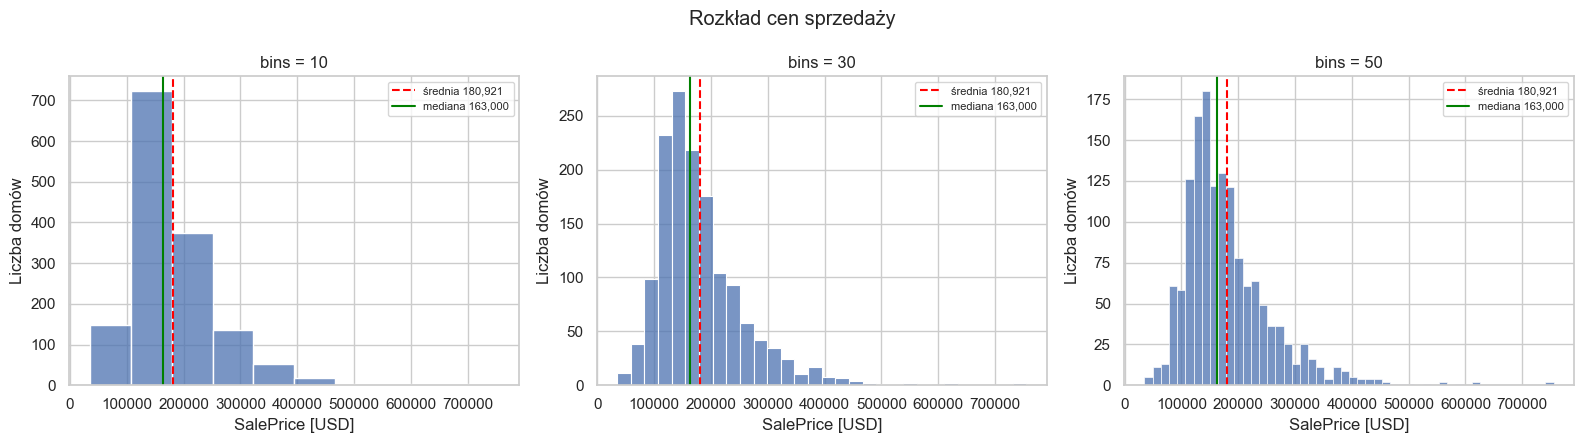

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, bins in zip(axes, [10, 30, 50]):
    sns.histplot(price, bins=bins, ax=ax)
    ax.axvline(price.mean(), color="red", ls="--", label=f"średnia {price.mean():,.0f}")
    ax.axvline(price.median(), color="green", ls="-", label=f"mediana {price.median():,.0f}")
    ax.set(title=f"bins = {bins}", xlabel="SalePrice [USD]", ylabel="Liczba domów")
    ax.legend(fontsize=8)
plt.suptitle("Rozkład cen sprzedaży")
plt.tight_layout()
plt.show()

- **bins = 10** — za mało przedziałów; widać skośność, ale ginie kształt szczytu.
- **bins = 30** — dobry kompromis: wyraźny szczyt ok. 130–160 tys. i długi prawy ogon.
- **bins = 50** — więcej szczegółów, ale pojawia się „szum” (puste/poszarpane słupki w ogonie).

Rozkład jest **prawostronnie skośny** (skośność ≈ 1,88): średnia (≈ 181 tys.) > mediana (163 tys.) —
średnią ciągnie w górę ogon bardzo drogich domów.

### Wykres pudełkowy cen — wartości odstające

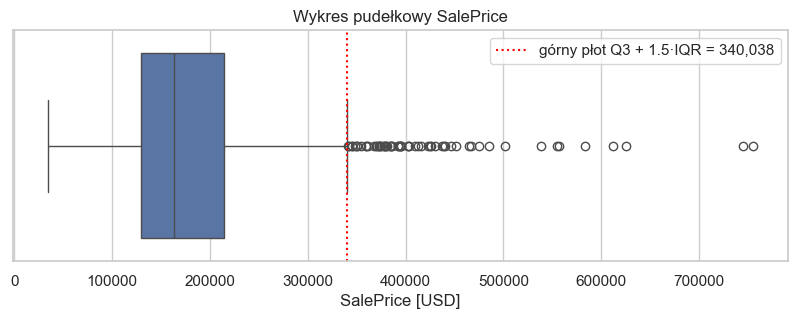

Płoty: [3,938, 340,038]
Kandydaci na wartości odstające: 61 domów (4.2%), wszystkie powyżej górnego płotu


In [16]:
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(price < lower_fence) | (price > upper_fence)]

fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=price, ax=ax)
ax.axvline(upper_fence, color="red", ls=":", label=f"górny płot Q3 + 1.5·IQR = {upper_fence:,.0f}")
ax.set(title="Wykres pudełkowy SalePrice", xlabel="SalePrice [USD]")
ax.legend()
plt.show()

print(f"Płoty: [{lower_fence:,.0f}, {upper_fence:,.0f}]")
print(f"Kandydaci na wartości odstające: {len(outliers)} domów ({len(outliers)/len(df):.1%}), wszystkie powyżej górnego płotu")

In [17]:
# Co to za bardzo drogie domy?
cols = ["SalePrice", "OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars", "YearBuilt", "Neighborhood"]
print("Mediany: drogie domy (outliers) vs reszta")
pd.DataFrame({
    "odstające (> płot)": outliers[cols[:-1]].median(),
    "pozostałe": df.drop(outliers.index)[cols[:-1]].median(),
})

Mediany: drogie domy (outliers) vs reszta


,odstające (> płot),pozostałe
SalePrice,"394,617.00","159,500.00"
OverallQual,9.00,6.00
GrLivArea,"2,364.00","1,437.00"
TotalBsmtSF,"1,856.00",973.00
GarageCars,3.00,2.00
YearBuilt,"2,006.00","1,971.00"


In [18]:
outliers["Neighborhood"].value_counts().head(6)

Neighborhood
NridgHt    27
NoRidge    11
StoneBr     9
Timber      3
Crawfor     3
CollgCr     2
Name: count, dtype: int64

Domy powyżej górnego płotu (≈ 340 tys. USD) to **nie błędy**, tylko nieruchomości z górnej półki:
wyraźnie większe, nowsze, o wysokiej jakości (mediana `OverallQual` = 9) i z prestiżowych dzielnic
(NoRidge, NridgHt, StoneBr). Wykres pudełkowy oznacza je jako odstające, bo rozkład jest skośny —
**nie oznacza to, że należy je usunąć**.

### Czy ceny mają rozkład normalny?

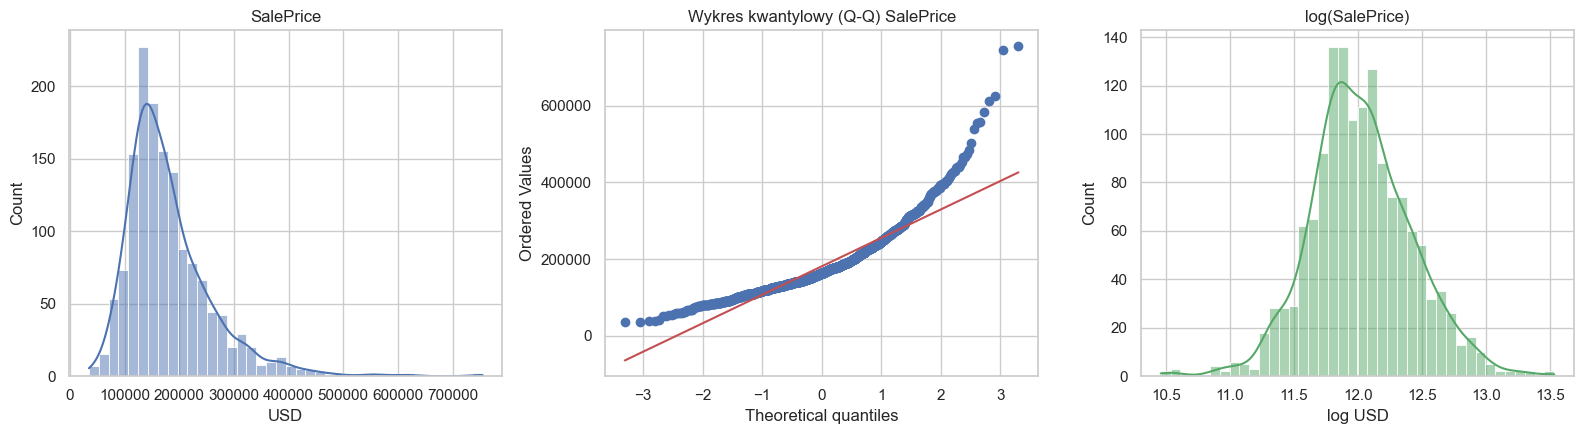

Skośność SalePrice:       1.883
Skośność log(SalePrice):  0.121
Test Shapiro-Wilka p-value (SalePrice):      3.21e-33
Test Shapiro-Wilka p-value (log SalePrice):  1.15e-07


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(price, kde=True, bins=40, ax=axes[0])
axes[0].set(title="SalePrice", xlabel="USD")
stats.probplot(price, dist="norm", plot=axes[1])
axes[1].set_title("Wykres kwantylowy (Q-Q) SalePrice")
log_price = np.log(price)
sns.histplot(log_price, kde=True, bins=40, ax=axes[2], color="C2")
axes[2].set(title="log(SalePrice)", xlabel="log USD")
plt.tight_layout()
plt.show()

print(f"Skośność SalePrice:       {price.skew():.3f}")
print(f"Skośność log(SalePrice):  {log_price.skew():.3f}")
print(f"Test Shapiro-Wilka p-value (SalePrice):      {stats.shapiro(price).pvalue:.2e}")
print(f"Test Shapiro-Wilka p-value (log SalePrice):  {stats.shapiro(log_price).pvalue:.2e}")

- Histogram **nie jest symetryczny**, a na wykresie Q-Q punkty odginają się od prostej w prawym ogonie →
  ceny **nie mają rozkładu normalnego** (potwierdza to test Shapiro-Wilka, p ≪ 0,05).
- Po logarytmowaniu rozkład staje się niemal symetryczny (skośność ≈ 0,12). Test Shapiro-Wilka formalnie nadal
  odrzuca normalność (przy n = 1460 wykrywa nawet drobne odchylenia), ale kształt jest bliski normalnemu. Przy modelowaniu
  (np. regresja liniowa) warto przewidywać `log(SalePrice)`.

## 4. Wykresy podobne do tych z wykładu

### Wykres pudełkowy — cena a ogólna jakość domu (`OverallQual`)

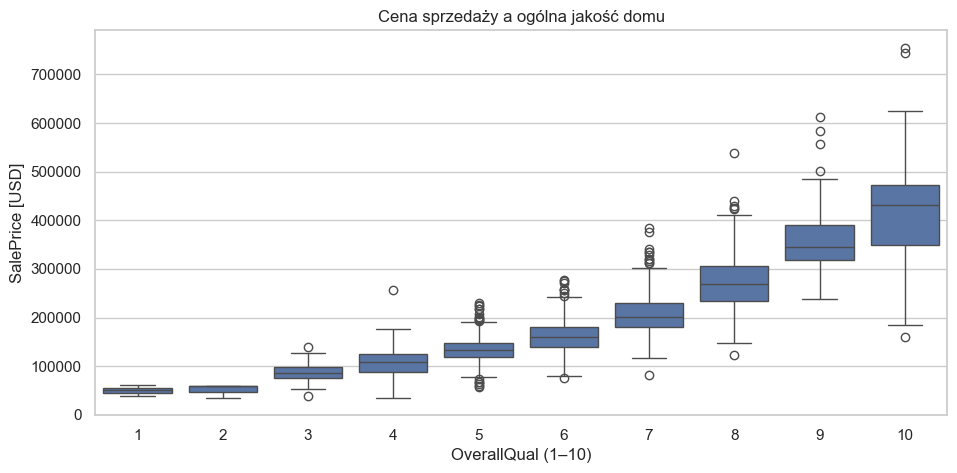

,count,median
OverallQual,,
1,2,"50,150.00"
2,3,"60,000.00"
3,20,"86,250.00"
4,116,"108,000.00"
5,397,"133,000.00"
6,374,"160,000.00"
7,319,"200,141.00"
8,168,"269,750.00"
9,43,"345,000.00"


In [20]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=ax, color="C0")
ax.set(title="Cena sprzedaży a ogólna jakość domu", xlabel="OverallQual (1–10)", ylabel="SalePrice [USD]")
plt.show()

df.groupby("OverallQual")["SalePrice"].agg(["count", "median"])

Cena rośnie wyraźnie (nieliniowo) z jakością. Ale w grupie **10** są dwa domy sprzedane poniżej 200 tys. USD —
sprawdzamy je niżej (sekcja 5).

### Wykres słupkowy — typ instalacji elektrycznej (`Electrical`)

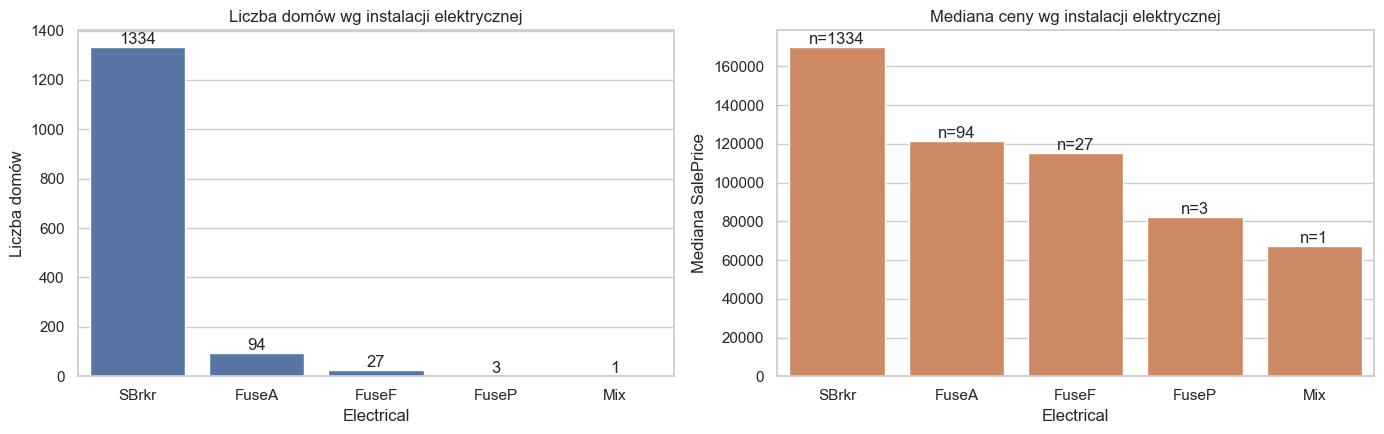

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = df["Electrical"].value_counts().index
sns.countplot(data=df, x="Electrical", order=order, ax=axes[0])
axes[0].set(title="Liczba domów wg instalacji elektrycznej", ylabel="Liczba domów")
for c in axes[0].containers:
    axes[0].bar_label(c)

med = df.groupby("Electrical")["SalePrice"].median().reindex(order)
cnt = df["Electrical"].value_counts().reindex(order)
sns.barplot(x=med.index, y=med.values, ax=axes[1], color="C1")
axes[1].set(title="Mediana ceny wg instalacji elektrycznej", xlabel="Electrical", ylabel="Mediana SalePrice")
axes[1].bar_label(axes[1].containers[0], labels=[f"n={n}" for n in cnt])
plt.tight_layout()
plt.show()

- 91% domów ma standardowe wyłączniki (`SBrkr`) → cecha słabo różnicuje domy.
- Rzadkie kategorie (bezpieczniki `FuseA/F/P`, `Mix`) wiążą się z niższą ceną — ale mediana z n = 1 czy n = 3
  niewiele znaczy. To raczej sygnał „stary dom” niż samodzielny czynnik.

### Wykres liniowy — liczba sprzedaży w kolejnych miesiącach

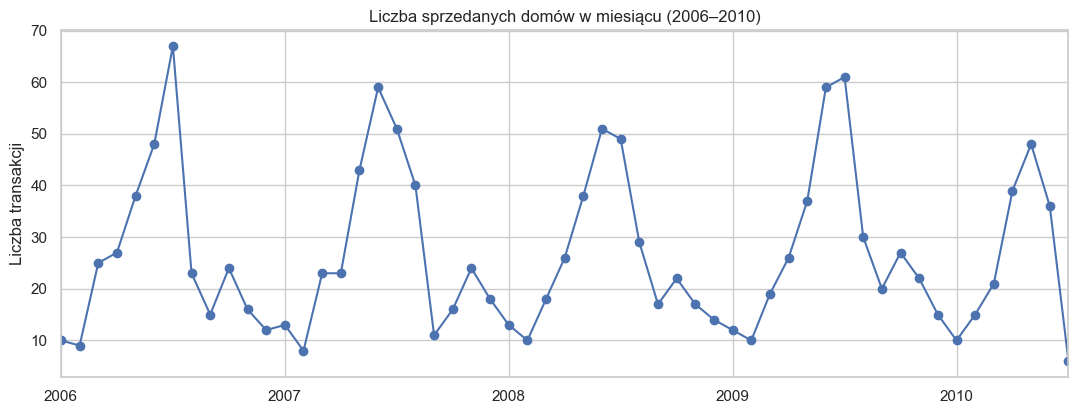

In [22]:
sales = (df.assign(data=pd.to_datetime(dict(year=df["YrSold"], month=df["MoSold"], day=1)))
           .groupby("data").size())

fig, ax = plt.subplots(figsize=(13, 4.5))
sales.plot(ax=ax, marker="o")
ax.set(title="Liczba sprzedanych domów w miesiącu (2006–2010)", xlabel="", ylabel="Liczba transakcji")
plt.show()

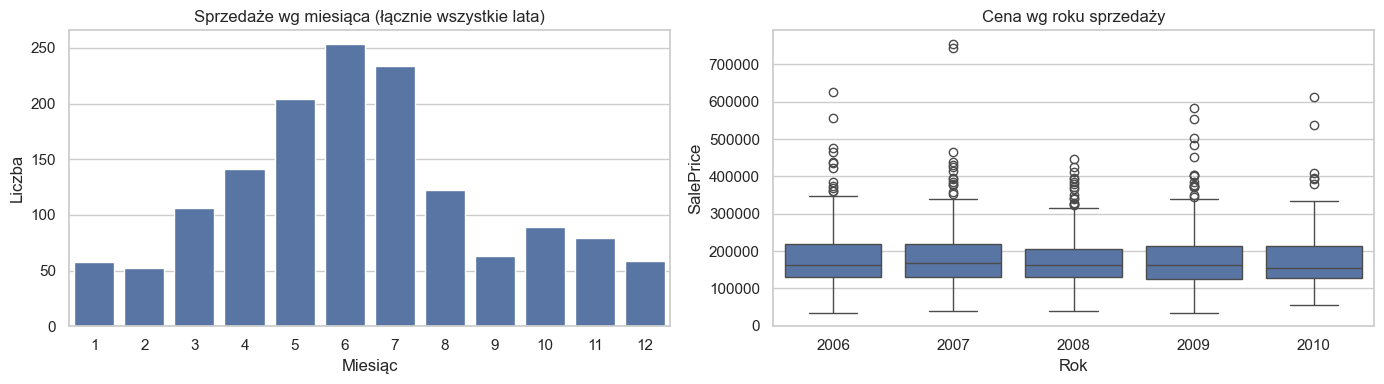

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df, x="MoSold", ax=axes[0], color="C0")
axes[0].set(title="Sprzedaże wg miesiąca (łącznie wszystkie lata)", xlabel="Miesiąc", ylabel="Liczba")
sns.boxplot(data=df, x="YrSold", y="SalePrice", ax=axes[1])
axes[1].set(title="Cena wg roku sprzedaży", xlabel="Rok", ylabel="SalePrice")
plt.tight_layout()
plt.show()

- Wyraźna **sezonowość**: szczyt sprzedaży w maju–lipcu, dołki zimą.
- Spadek na końcu wykresu to **koniec zbioru** (dane do lipca 2010), a nie trend.
- Mediana cen w kolejnych latach jest bardzo stabilna — kryzys 2008 nie jest wyraźnie widoczny w cenach z Ames.

### Mapa ciepła korelacji — wiele zmiennych naraz

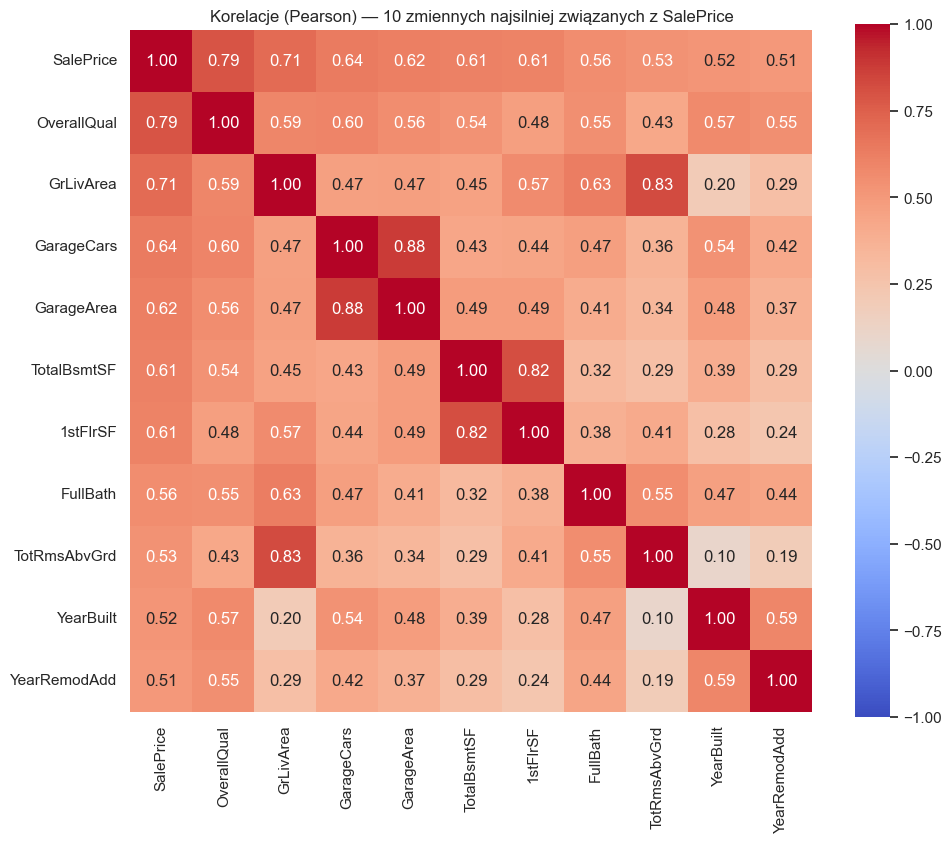

In [24]:
corr = df.select_dtypes("number").drop(columns="Id").corr()
top = corr["SalePrice"].abs().sort_values(ascending=False).head(11).index

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(df[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Korelacje (Pearson) — 10 zmiennych najsilniej związanych z SalePrice")
plt.show()

- Najsilniej z ceną skorelowane są: `OverallQual` (0,79), `GrLivArea` (0,71), `GarageCars`/`GarageArea` (≈ 0,63),
  `TotalBsmtSF`/`1stFlrSF` (≈ 0,61).
- Widać też **silnie skorelowane pary cech** (współliniowość): `GarageCars`–`GarageArea` (0,88),
  `TotalBsmtSF`–`1stFlrSF` (0,82), `GrLivArea`–`TotRmsAbvGrd` (0,83). W modelu wystarczy zwykle jedna z pary.

### Pairplot — kilka kluczowych zmiennych

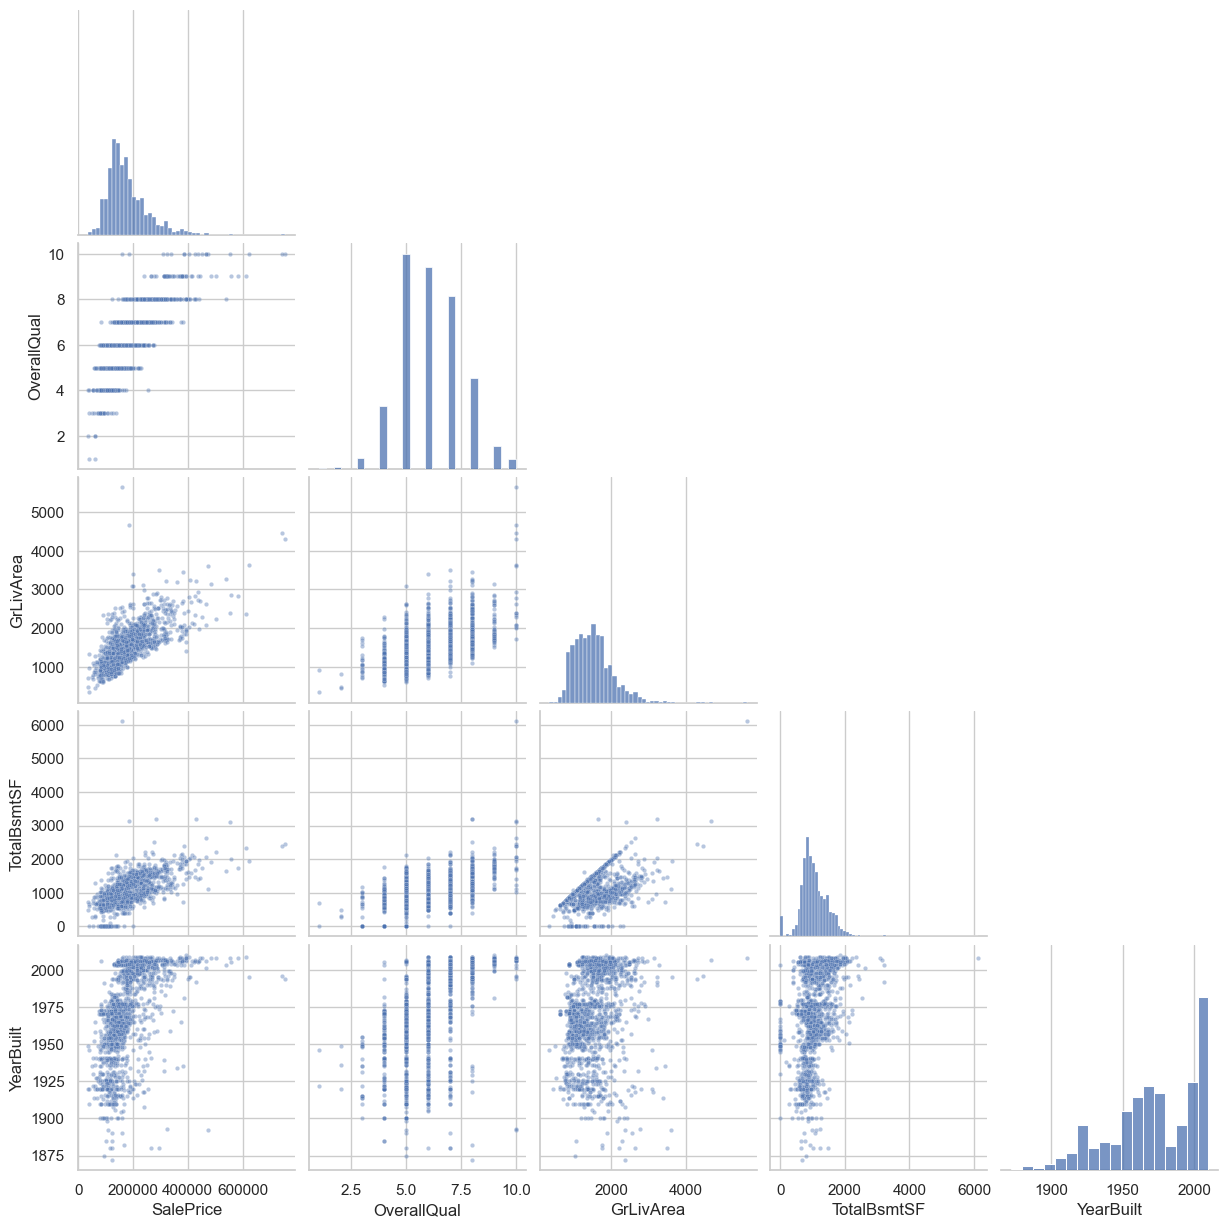

In [25]:
sns.pairplot(df[["SalePrice", "OverallQual", "GrLivArea", "TotalBsmtSF", "YearBuilt"]],
             corner=True, plot_kws=dict(s=10, alpha=0.4))
plt.show()

## 5. Co wpływa na cenę domu?

**Hipoteza:** „Większe domy są droższe”.

### Zmienne związane z powierzchnią
Szukamy „Area” i „SF” (*square feet*) w nazwach kolumn. Uwaga na jednostki: stopy² (1 ft² ≈ 0,093 m²) i USD.

In [26]:
area_cols = [c for c in df.columns if "Area" in c or "SF" in c]
print(area_cols)

area_corr = pd.DataFrame({
    "Pearson": df[area_cols].corrwith(df["SalePrice"]),
    "Spearman": df[area_cols].corrwith(df["SalePrice"], method="spearman"),
}).sort_values("Pearson", ascending=False)
area_corr

['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'PoolArea']


,Pearson,Spearman
GrLivArea,0.71,0.73
GarageArea,0.62,0.65
TotalBsmtSF,0.61,0.60
1stFlrSF,0.61,0.58
MasVnrArea,0.48,0.42
BsmtFinSF1,0.39,0.30
WoodDeckSF,0.32,0.35
2ndFlrSF,0.32,0.29
OpenPorchSF,0.32,0.48
LotArea,0.26,0.46


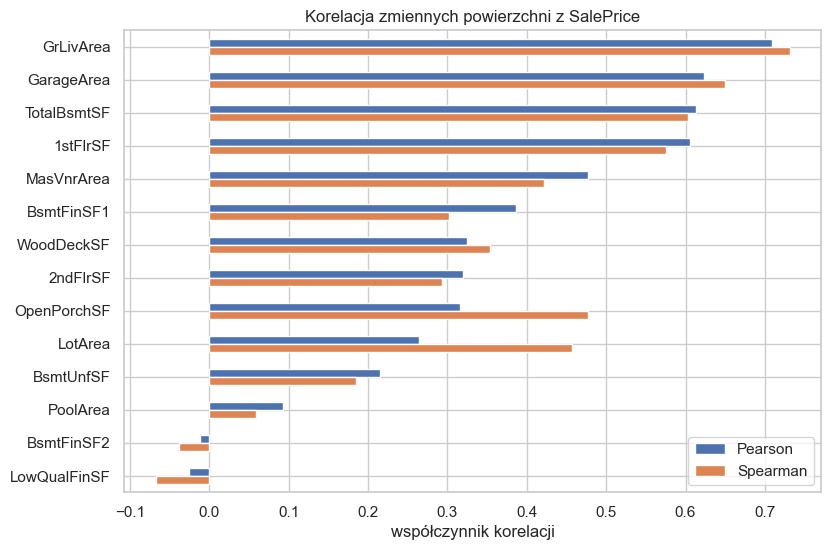

In [27]:
ax = area_corr.plot.barh(figsize=(9, 6))
ax.invert_yaxis()
ax.set(title="Korelacja zmiennych powierzchni z SalePrice", xlabel="współczynnik korelacji")
plt.show()

### Wykres punktowy: powierzchnia mieszkalna (`GrLivArea`) vs cena

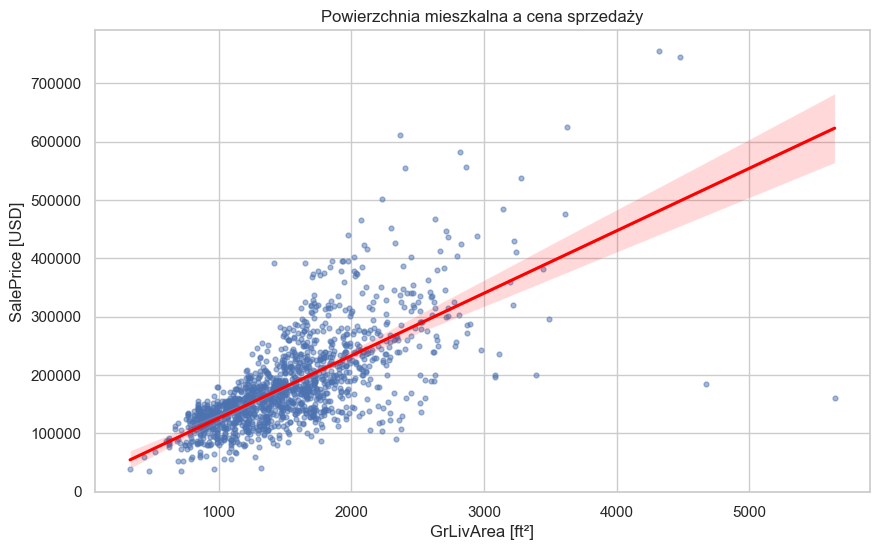

Korelacja Pearsona: 0.709


In [28]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=df, x="GrLivArea", y="SalePrice", ax=ax,
            scatter_kws=dict(s=12, alpha=0.5), line_kws=dict(color="red"))
ax.set(title="Powierzchnia mieszkalna a cena sprzedaży",
       xlabel="GrLivArea [ft²]", ylabel="SalePrice [USD]")
plt.show()
print(f"Korelacja Pearsona: {df['GrLivArea'].corr(df['SalePrice']):.3f}")

- Zależność jest **wyraźna i dodatnia** — większe domy zwykle są droższe. Hipoteza się potwierdza.
- Jest w przybliżeniu liniowa, ale rozrzut cen **rośnie wraz z powierzchnią** (kształt „lejka”, heteroskedastyczność).
- W prawym dolnym rogu są **dwa dziwne punkty**: ogromne domy (> 4500 ft²) za mniej niż 200 tys. USD.

### Dziwne obserwacje — kim one są?

In [29]:
big = df[df["GrLivArea"] > 4000]
big[["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition", "SaleType", "Neighborhood", "YearBuilt"]]

,Id,GrLivArea,SalePrice,OverallQual,SaleCondition,SaleType,Neighborhood,YearBuilt
523,524,4676,184750,10,Partial,New,Edwards,2007
691,692,4316,755000,10,Normal,WD,NoRidge,1994
1182,1183,4476,745000,10,Abnorml,WD,NoRidge,1996
1298,1299,5642,160000,10,Partial,New,Edwards,2008


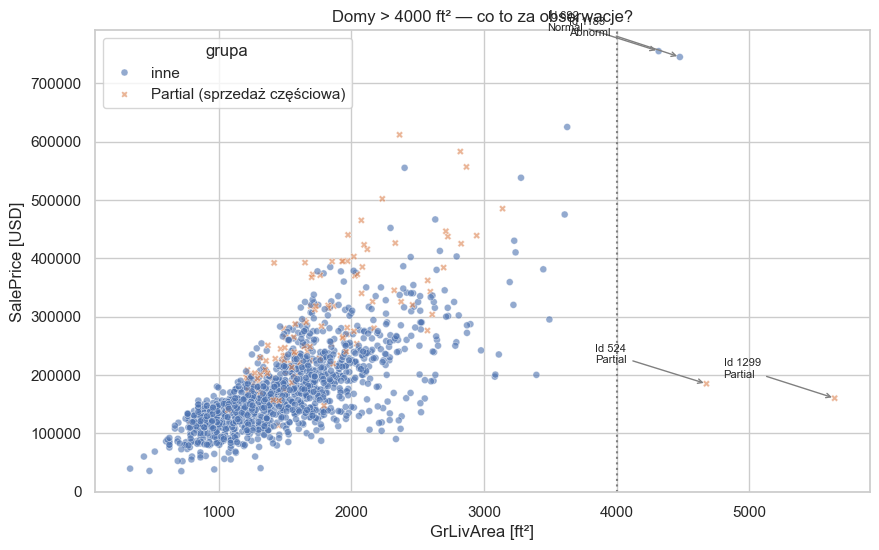

In [30]:
df_plot = df.assign(grupa=np.where(df["SaleCondition"] == "Partial", "Partial (sprzedaż częściowa)", "inne"))
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_plot, x="GrLivArea", y="SalePrice", hue="grupa", style="grupa", s=25, alpha=0.6, ax=ax)
for _, r in big.iterrows():
    ax.annotate(f"Id {r.Id}\n{r.SaleCondition}", (r.GrLivArea, r.SalePrice),
                xytext=(-80, 15), textcoords="offset points", fontsize=8,
                arrowprops=dict(arrowstyle="->", color="gray"))
ax.axvline(4000, color="gray", ls=":")
ax.set(title="Domy > 4000 ft² — co to za obserwacje?", xlabel="GrLivArea [ft²]", ylabel="SalePrice [USD]")
plt.show()

- Domy **Id 524 i 1299** mają najwyższą jakość (10), są największe w zbiorze (4676 i 5642 ft²), a kosztowały
  < 200 tys. USD. Oba to **sprzedaże częściowe** (`SaleCondition = Partial` — dom niedokończony w momencie wyceny),
  w dzielnicy Edwards. Ich cena nie odzwierciedla wartości rynkowej.
- To są te same dwa domy z grupy „10” na wykresie pudełkowym w sekcji 4.
- Pozostałe dwa duże domy (Id 692, 1183) mają ceny zgodne z trendem — to po prostu najdroższe domy w zbiorze.
- Autor zbioru (De Cock, 2011) zaleca usunięcie domów > 4000 ft² — **z uzasadnieniem**, a nie dlatego, że „odstają”.

In [31]:
df_no = df[df["GrLivArea"] <= 4000]
print(f"Korelacja GrLivArea–SalePrice: przed = {df['GrLivArea'].corr(df['SalePrice']):.3f}, "
      f"po usunięciu domów > 4000 ft² = {df_no['GrLivArea'].corr(df_no['SalePrice']):.3f}")

Korelacja GrLivArea–SalePrice: przed = 0.709, po usunięciu domów > 4000 ft² = 0.721


### Dodatkowo: czy powierzchnia działki (`LotArea`) ma taki sam wpływ jak powierzchnia domu?
Porównujemy wykresy punktowe 3 rodzajów powierzchni.

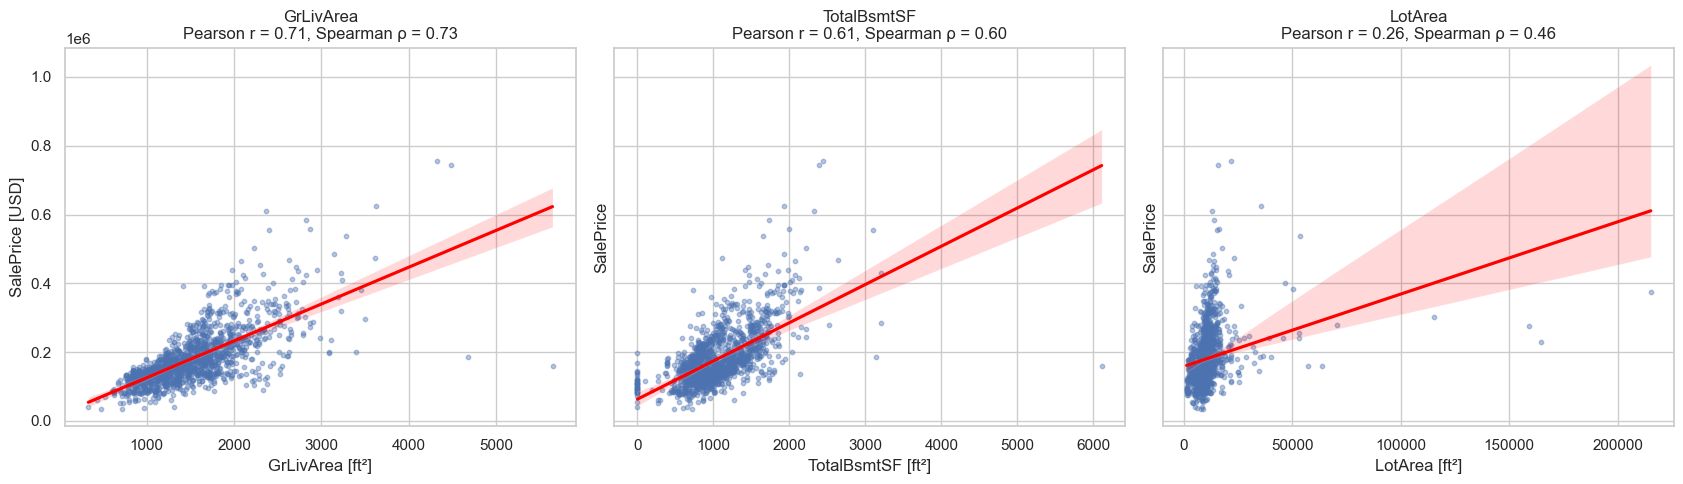

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, col in zip(axes, ["GrLivArea", "TotalBsmtSF", "LotArea"]):
    sns.regplot(data=df, x=col, y="SalePrice", ax=ax,
                scatter_kws=dict(s=10, alpha=0.4), line_kws=dict(color="red"))
    r = df[col].corr(df["SalePrice"])
    rs = df[col].corr(df["SalePrice"], method="spearman")
    ax.set(title=f"{col}\nPearson r = {r:.2f}, Spearman ρ = {rs:.2f}", xlabel=f"{col} [ft²]")
axes[0].set_ylabel("SalePrice [USD]")
plt.tight_layout()
plt.show()

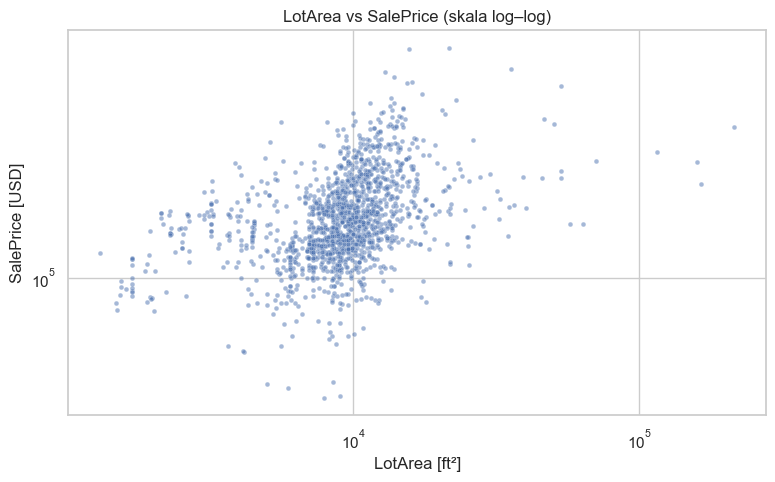

Korelacja log(LotArea)–log(SalePrice): 0.400
LotArea: mediana = 9,478 ft², max = 215,245 ft²


In [33]:
# LotArea ma bardzo długi ogon — zobaczmy w skali logarytmicznej
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x="LotArea", y="SalePrice", s=12, alpha=0.5, ax=ax)
ax.set(xscale="log", yscale="log", title="LotArea vs SalePrice (skala log–log)",
       xlabel="LotArea [ft²]", ylabel="SalePrice [USD]")
plt.show()
print(f"Korelacja log(LotArea)–log(SalePrice): {np.log(df['LotArea']).corr(np.log(df['SalePrice'])):.3f}")
print(f"LotArea: mediana = {df['LotArea'].median():,.0f} ft², max = {df['LotArea'].max():,.0f} ft²")

- **`GrLivArea`** (powierzchnia mieszkalna nad ziemią) ma **najsilniejszy** związek z ceną (r ≈ 0,71, ρ ≈ 0,73).
- **`TotalBsmtSF`** (piwnica) — też silny (r ≈ 0,61); widać grupę domów z wartością 0 (brak piwnicy) i jeden ogromny
  odstający punkt (to znowu Id 1299).
- **`LotArea`** (działka) ma **znacznie słabszy** wpływ (r ≈ 0,26). Kilka gigantycznych działek (do 215 tys. ft²)
  nie ma wyższych cen. W skali logarytmicznej związek jest wyraźniejszy (r ≈ 0,4), ale nadal słabszy niż dla
  powierzchni domu. Spearman (0,46) > Pearson (0,26) — zależność jest monotoniczna, ale nieliniowa i zaburzona przez
  wartości skrajne.
- Wniosek: liczy się przede wszystkim **powierzchnia domu**, a nie działki.

### Bonus: dzielnica i cena

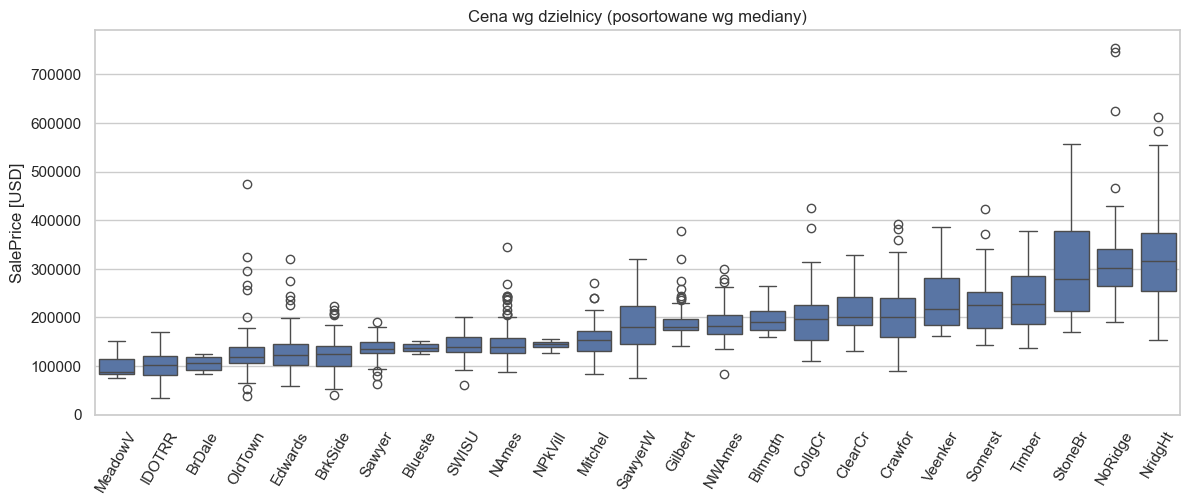

In [34]:
order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=order, ax=ax, color="C0")
ax.tick_params(axis="x", rotation=60)
ax.set(title="Cena wg dzielnicy (posortowane wg mediany)", xlabel="", ylabel="SalePrice [USD]")
plt.show()

Lokalizacja ma ogromne znaczenie: mediany cen dzielnic różnią się ponad trzykrotnie
(MeadowV, IDOTRR, BrDale ≈ 90–105 tys. vs NoRidge, NridgHt, StoneBr ≈ 280–315 tys.).

## 6. Wnioski

1. **Zmienna docelowa** to `SalePrice`. Rozkład jest **prawostronnie skośny** (średnia 180 921 > mediana 163 000 USD,
   skośność 1,88) i **nie jest normalny**. Logarytm ceny jest niemal symetryczny — dobry kandydat na target w modelu.
2. **Statystyki ceny:** min 34 900, Q1 129 975, mediana 163 000, Q3 214 000, max 755 000 USD; IQR = 84 025 USD.
   61 domów leży powyżej górnego płotu (≈ 340 tys.) — to prawdziwe, luksusowe domy, nie błędy.
3. **Braki danych:** większość „braków” to w rzeczywistości **brak cechy** (basen, alejka, ogrodzenie, kominek,
   garaż, piwnica) — pandas zamienia też tekst `"None"` w `MasVnrType` na NaN. Prawdziwych braków jest mało
   (głównie `LotFrontage`). Zanim zaczniemy „czyścić”, trzeba przeczytać `data_description.txt`.
4. **Hipoteza „większe domy są droższe” — potwierdzona.** `GrLivArea` ma najsilniejszy związek z ceną spośród
   zmiennych powierzchni (r ≈ 0,71); powierzchnia działki (`LotArea`) — dużo słabszy (r ≈ 0,26).
5. **Najważniejsze czynniki ceny:** ogólna jakość (`OverallQual`, r ≈ 0,79), powierzchnia mieszkalna, garaż,
   piwnica, rok budowy i **dzielnica**.
6. **Dziwne obserwacje:** dwa największe domy (Id 524, 1299) sprzedane tanio to sprzedaże częściowe (`Partial`).
   Ich usunięcie jest uzasadnione merytorycznie (zalecenie autora zbioru), a nie tylko dlatego, że „odstają”.
7. **Sezonowość:** najwięcej transakcji w maju–lipcu; ceny w latach 2006–2010 stabilne.
8. **Współliniowość:** pary `GarageCars`/`GarageArea`, `TotalBsmtSF`/`1stFlrSF`, `GrLivArea`/`TotRmsAbvGrd` niosą
   podobną informację — warto o tym pamiętać przy budowie modelu.
9. **Zakres zbioru:** tylko domy (jednorodzinne, szeregowce, bliźniaki, dwurodzinne) z jednego miasta w USA —
   model nie przeniesie się wprost na polski rynek mieszkań w blokach.